# A1 Images à annoter

Objectif : choisir les images à corriger, parmi les images déjà pré-annotées du train, du val et du test.

- On part des masques d'origine : on les corrige (décalage, largeur, fentes), on ne repart pas de zéro. On garde les conventions des annotateurs, y compris les racines très fines.
- Images en 150 DPI : BAZ 2015, BAZ 2016, CZ 2016.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from prmi import viz
from prmi.annotation_pool import GROUPS, POOL, QUOTAS, build_pool
from prmi.diagnostic import load_pair, overlay_mask
from prmi.image_stats import HARD_TYPES, image_type, load_image_stats

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 60

d = load_image_stats()
d['type'] = image_type(d)
train = d[(d['split'] == 'train') & (d['dpi'] == 150)]       # images dans lesquelles on tire le lot

## 1. La diversité des images et de leurs annotations

20 images du train tirées au hasard (avec ou sans racine), avec leur masque d'origine en bleu.

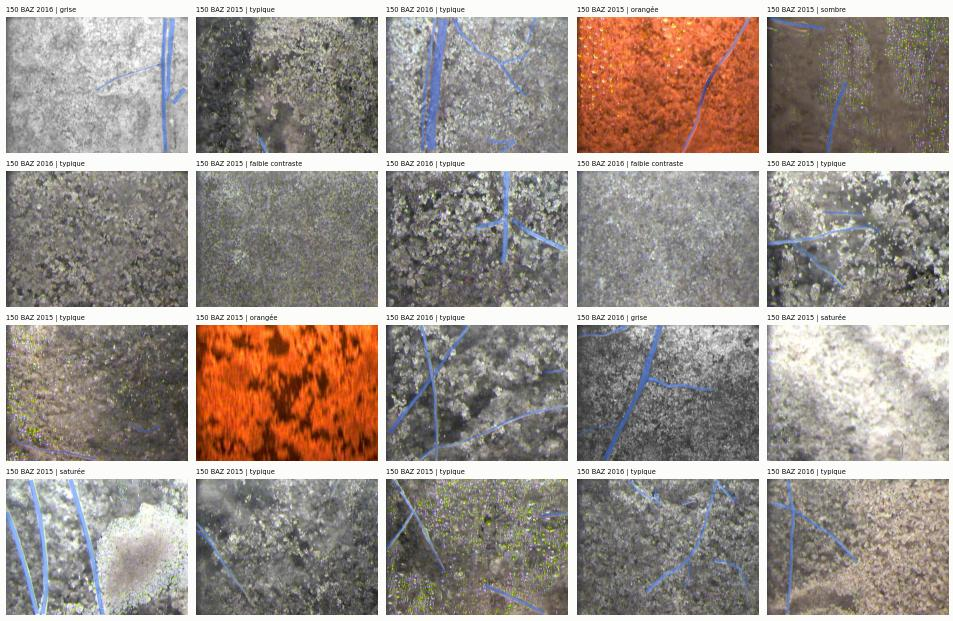

In [2]:
ex = train.sample(20, random_state=0)
fig, axes = plt.subplots(4, 5, figsize=(16, 10.5))
for ax, (_, r) in zip(axes.flat, ex.iterrows()):
    img, m = load_pair(r) if r['mask_path'] else (None, None)
    ax.imshow(overlay_mask(img, m))
    ax.set_title(f"{r['group']} | {r['type']}", loc='left', fontsize=8)
    ax.axis('off')
fig.tight_layout()
viz.save(fig, 'A1_diversite.jpg')

- 44 % des images du train n'ont pas de racine (5 sur 20 ici) : masque vide.
- Grande variété : sol clair ou sombre, gris ou orangé, gouttes sur la paroi, surexposition, flou.
- Annotations : chaînes de segments rectilignes, de la racine fine à la grosse racine.

## 2. Combien d'images ?

**273 images** : 149 du train, 74 du val, 50 du test, chacune tirée dans son propre split (aucun tube commun).

- Train : 85 images avec racine, un premier ordre de grandeur à confirmer par une courbe d'apprentissage (25, 50, 85 images), et 64 sans racine.
- Val : 42 images avec racine sur les 8 tubes du val, et 32 sans racine. Toutes les décisions se prennent dessus (augmentations, prétraitement, boucles de réentraînement), en comparant les variantes image par image.
- Test : 50 images tirées au hasard, représentatives du test officiel. Évaluation finale seulement, une seule fois.
- Images sans racine à la proportion réelle de chaque groupe (environ 43 % au total, comme dans les trois splits) : le modèle doit voir les leurres (gouttes, reflets, sol clair) sans racine à côté. Elles se vérifient vite, rien à dessiner.

## 3. Composition du lot

Train et val : tirage au hasard sous quotas, par groupe (`src/prmi/annotation_pool.py`). Cas difficiles avec racine sur-représentés, cas courants répartis par profondeur et par densité de racine, au plus 4 images par tube et par campagne (6 dans le val, qui n'a que 4 tubes par campagne). Images sans racine à la proportion réelle du groupe, tirées au hasard : leur répartition par date, profondeur et tube est donc celle des données.

Test : tirage au hasard dans chaque groupe, au prorata de la taille des groupes, sans autre contrainte.

In [3]:
pool = build_pool(d)
pool['catégorie'] = np.where(pool['has_root'], pool['type'], 'sans racine')
cols = ['sans racine', 'typique'] + HARD_TYPES
tab = pool.groupby(['lot', 'group'])['catégorie'].value_counts().unstack(fill_value=0).reindex(columns=cols, fill_value=0)
tab['total'] = tab.sum(axis=1)
tab

catégorie           sans racine  typique  orangée  grise  saturée  faible contraste  sombre  total
lot   group                                                                                       
test  150 BAZ 2015           14       12        0      0        1                 0       1     28
      150 BAZ 2016            4       11        0      3        0                 0       1     19
      150 CZ 2016             1        2        0      0        0                 0       0      3
train 150 BAZ 2015           40       25        5      0        4                 2       2     78
      150 BAZ 2016           16       22        0      5        2                 2       3     50
      150 CZ 2016             8       10        0      0        0                 1       2     21
val   150 BAZ 2015           20       11        2      0        2                 1       1     37
      150 BAZ 2016            7        9        0      3        1                 1       1     22
      150 CZ 2016             5        7        0      0        0                 1       2     15

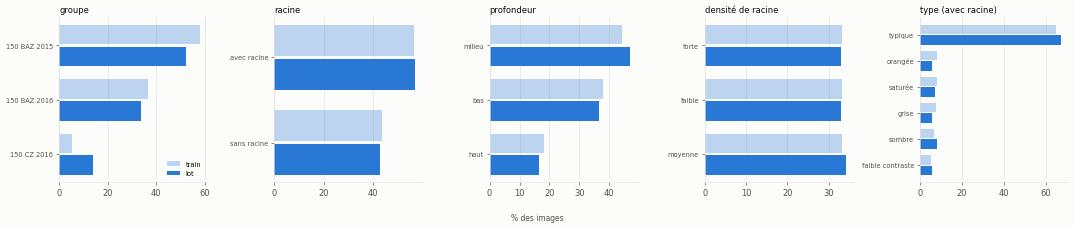

In [4]:
# Lot d'entraînement contre l'ensemble du train 150 DPI, en % des images
lot = pool[pool['lot'] == 'train']
q = train.loc[train['has_root'], 'root_frac'].quantile([1 / 3, 2 / 3]).tolist()


def view(f):
    rooted = f['has_root']
    return pd.DataFrame({
        'groupe': f['group'],
        'racine': np.where(rooted, 'avec racine', 'sans racine'),
        'profondeur': pd.cut(f['position'], [0, 35, 70, 200], labels=['haut', 'milieu', 'bas']).astype(str).where(rooted),
        'densité de racine': pd.cut(f['root_frac'], [0] + q + [1], labels=['faible', 'moyenne', 'forte']).astype(str).where(rooted),
        'type (avec racine)': f['type'].where(rooted),
    })


a, b = view(train), view(lot)
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, col in zip(axes, a.columns):
    pa, pb = 100 * a[col].value_counts(normalize=True), 100 * b[col].value_counts(normalize=True)
    cats = list(pa.index)[::-1]
    y = np.arange(len(cats))
    ax.barh(y + 0.2, [pa[c] for c in cats], height=0.36, color=viz.ACCENT, alpha=0.3, label='train')
    ax.barh(y - 0.2, [pb.get(c, 0) for c in cats], height=0.36, color=viz.ACCENT, label='lot')
    ax.set_yticks(y, cats, fontsize=8)
    ax.set_title(col, loc='left', fontsize=10)
    ax.grid(axis='y', visible=False)
axes[0].legend(frameon=False, fontsize=8)
fig.supxlabel('% des images', fontsize=9, color=viz.INK_2)
fig.tight_layout()
viz.save(fig, 'A1_composition.png')

- Profondeur, densité de racine et types d'images : proportions proches de celles du train.
- Images sans racine : 43 % du lot, 44 % du train.
- Cas difficiles : un tiers des images avec racine (33 % du lot, 35 % du train).
- Écart voulu : CZ 2016 sur-représenté (14 % du lot, 5 % du train : autre site).
- 25 tubes sur 28, les 7 dates de chaque campagne BAZ.

## 4. Quelques cas difficiles du lot

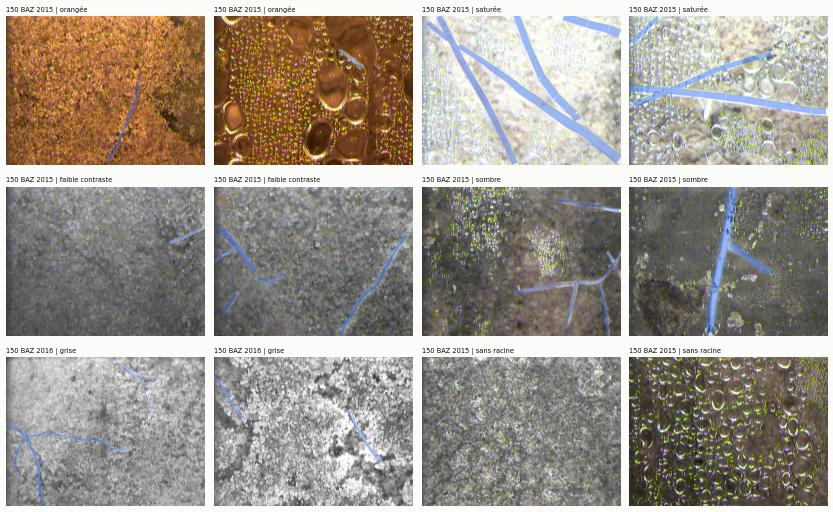

In [5]:
hard = lot[lot['has_root'] & lot['type'].isin(HARD_TYPES)].groupby('type').head(2)
empty = lot[~lot['has_root']].head(2)
ex = pd.concat([hard, empty])
fig, axes = plt.subplots(3, 4, figsize=(14, 8.8))
for ax, (_, r) in zip(axes.flat, ex.iterrows()):
    img, m = load_pair(r)
    ax.imshow(overlay_mask(img, m))
    ax.set_title(f"{r['group']} | {r['type'] if r['has_root'] else 'sans racine'}", loc='left', fontsize=8)
for ax in axes.flat:
    ax.axis('off')
fig.tight_layout()
viz.save(fig, 'A1_cas_difficiles.jpg')

- Cas variés mais annotés : racines fines, grosses racines en chaîne de rectangles (surexposé), racines sombres.
- Quelques masques douteux : un segment sur des gouttes (orangée, deuxième image), une racine à peine visible (faible contraste). Au cas par cas.
- Images sans racine : gouttes, sol granuleux, pièges à faux positifs.

## 5. Règles d'annotation

- On corrige les masques d'origine et on garde leurs conventions : racines fines incluses, même à 2 px.
- À corriger : décalage, largeur (toute la racine), fentes entre segments.
- Racine sombre sur sol clair : annotée comme les autres.
- Poils absorbants : pas annotés.
- Masque sans racine visible : supprimé, après vérification au cas par cas.
- Images sans racine (`has_root = 0`) : les regarder vraiment, des racines visibles peuvent ne pas être annotées.

In [6]:
POOL.parent.mkdir(parents=True, exist_ok=True)
pool.drop(columns='catégorie').to_csv(POOL, index=False)
print(len(pool), 'images ->', POOL.relative_to(POOL.parents[2]))

273 images -> data/processed/annotation_pool.csv


## 6. Export pour QuPath

Un dossier par lot (train, val, test) dans `data/interim/qupath/`, un sous-dossier par image : `image.jpg` (image d'origine, copiée telle quelle) et `mask.png` (masque d'origine, un canal, 0 ou 255). `lot.csv` donne le groupe, le type et la position de chaque image, avec une colonne `minutes` pour noter le temps d'annotation. Un lot déjà exporté n'est pas réécrit.

In [7]:
from prmi.qupath_io import export_pool

export_pool(pool);

train : 149 images -> data/interim/qupath/train


val : 74 images -> data/interim/qupath/val


test : 50 images -> data/interim/qupath/test
